In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


Up-regulated genes: 90
Down-regulated genes: 120


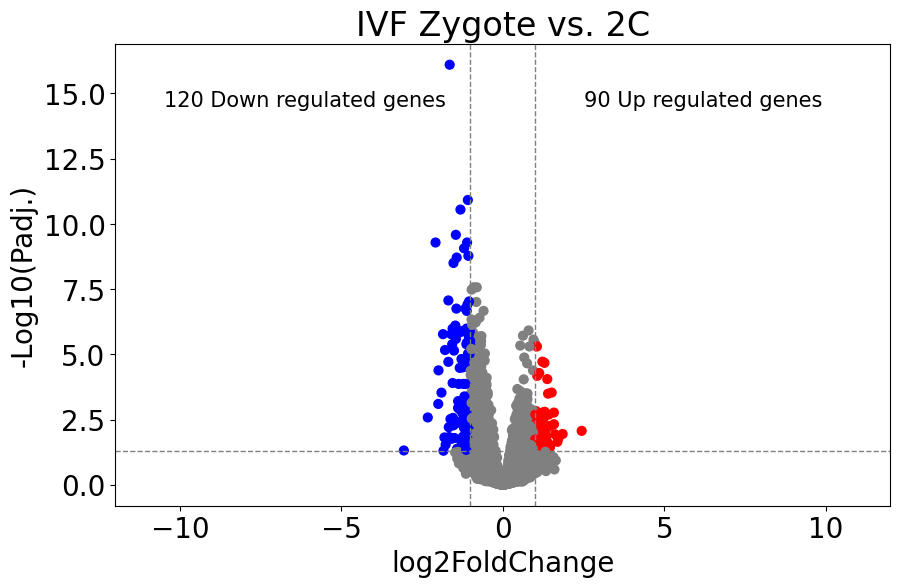

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据（请确认文件路径）
file_path = 'IVF_zygote_vs_2c.txt'
data = pd.read_csv(file_path, sep='\t')

# --- 数据预处理 ---
# 将 padj=0 替换为 NaN，避免 -log10(0) 产生 inf
data['padj'] = data['padj'].replace(0, np.nan)
# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'])

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理无穷值和缺失值（避免绘图和统计出错）
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# --- 统计上下调基因（基于阈值） ---
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated genes: {up_count}")
print(f"Down-regulated genes: {down_count}")

# --- 导出上下调基因 ID（假设第一列为基因名） ---
id_col = data.columns[0]
if up_count > 0:
    up_genes[[id_col]].to_csv("IVF_Zygote_vs_2C_upregulated_genes.txt", sep="\t", index=False)
if down_count > 0:
    down_genes[[id_col]].to_csv("IVF_Zygote_vs_2C_downregulated_genes.txt", sep="\t", index=False)

# --- 绘图 ---
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 动态定位文本注释
max_y = data['-log10(padj)'].max()
if not np.isnan(max_y) and max_y > 0:
    plt.text(-10.5, max_y * 0.9, f'{down_count} Down regulated genes',
             horizontalalignment='left', color='black', fontsize=15)
    plt.text(2.5, max_y * 0.9, f'{up_count} Up regulated genes',
             horizontalalignment='left', color='black', fontsize=15)

# 坐标轴与标题
plt.title('IVF Zygote vs. 2C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)  # 可根据数据范围动态调整

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'IVF_Zygote_2C_volcano.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated genes: 3331
Down-regulated genes: 2653


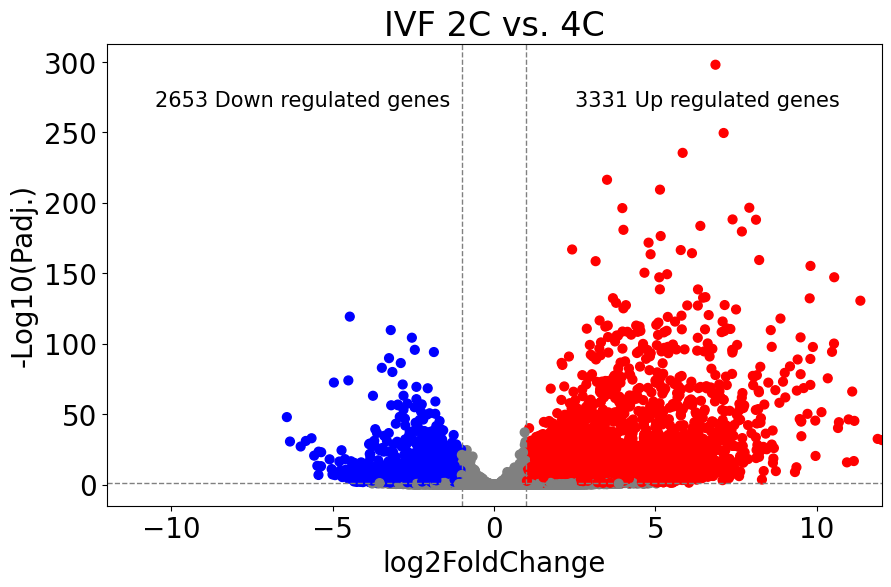

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据（请确认文件路径）
file_path = 'IVF_2c_vs_4c.txt'
data = pd.read_csv(file_path, sep='\t')

# --- 数据预处理 ---
# 将 padj=0 替换为 NaN，避免 -log10(0) 产生 inf
data['padj'] = data['padj'].replace(0, np.nan)
# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'])

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理无穷值和缺失值（避免绘图和统计出错）
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# --- 统计上下调基因（基于阈值） ---
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated genes: {up_count}")
print(f"Down-regulated genes: {down_count}")

# --- 导出上下调基因 ID（假设第一列为基因名） ---
id_col = data.columns[0]
if up_count > 0:
    up_genes[[id_col]].to_csv("IVF_2C_vs_4C_upregulated_genes.txt", sep="\t", index=False)
if down_count > 0:
    down_genes[[id_col]].to_csv("IVF_2C_vs_4C_downregulated_genes.txt", sep="\t", index=False)

# --- 绘图 ---
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 动态定位文本注释
max_y = data['-log10(padj)'].max()
if not np.isnan(max_y) and max_y > 0:
    plt.text(-10.5, max_y * 0.9, f'{down_count} Down regulated genes',
             horizontalalignment='left', color='black', fontsize=15)
    plt.text(2.5, max_y * 0.9, f'{up_count} Up regulated genes',
             horizontalalignment='left', color='black', fontsize=15)

# 坐标轴与标题
plt.title('IVF 2C vs. 4C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)  # 可根据数据范围动态调整

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'IVF_2C_4C_volcano.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated genes: 1863
Down-regulated genes: 2442


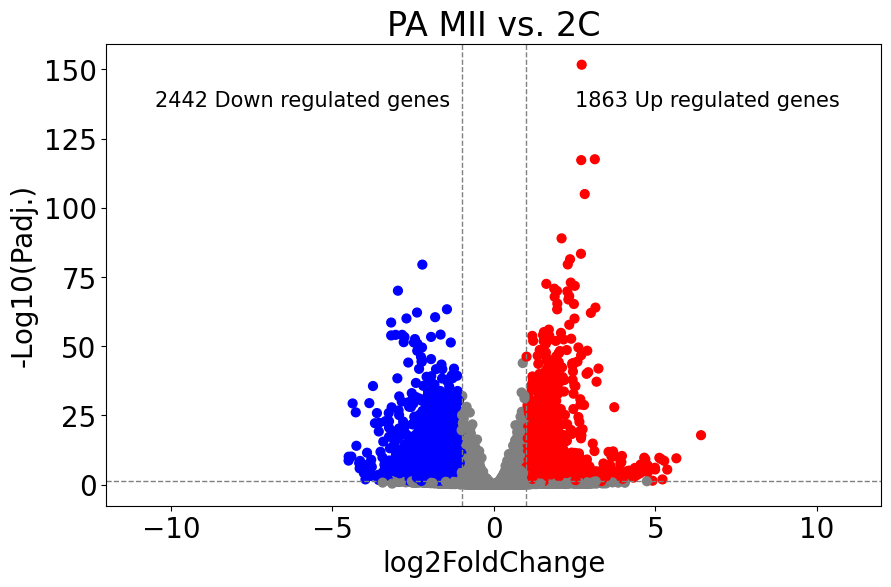

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据（请确认文件路径）
file_path = 'PA_mii_vs_2c.txt'
data = pd.read_csv(file_path, sep='\t')

# --- 数据预处理 ---
# 将 padj=0 替换为 NaN，避免 -log10(0) 产生 inf
data['padj'] = data['padj'].replace(0, np.nan)
# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'])

# 颜色分类
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理无穷值和缺失值（避免绘图出错）
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# --- 统计上下调基因（基于阈值） ---
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated genes: {up_count}")
print(f"Down-regulated genes: {down_count}")

# --- 绘图 ---
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 动态定位文本注释
max_y = data['-log10(padj)'].max()
plt.text(
    -10.5, max_y * 0.9,
    f'{down_count} Down regulated genes',
    horizontalalignment='left',
    color='black',
    fontsize=15
)
plt.text(
    2.5, max_y * 0.9,
    f'{up_count} Up regulated genes',
    horizontalalignment='left',
    color='black',
    fontsize=15
)

# 坐标轴与标题（移除标题尾随空格）
plt.title('PA MII vs. 2C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'PA_MII_2C_volcano.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated genes: 3832
Down-regulated genes: 2017


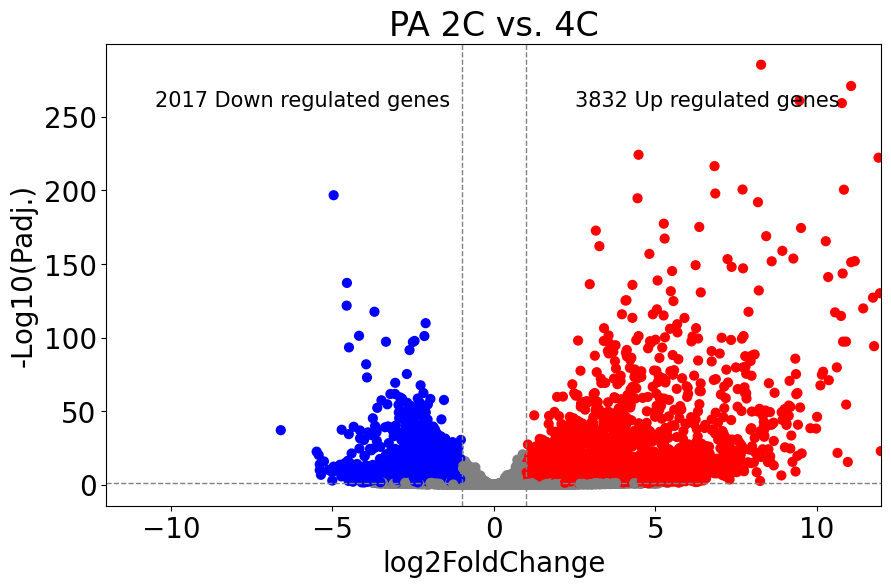

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据（请确认文件路径）
file_path = 'PA_2c_vs_4c.txt'
data = pd.read_csv(file_path, sep='\t')

# --- 数据预处理 ---
# padj=0 替换为 NaN，避免 -log10(0) 产生 inf
data['padj'] = data['padj'].replace(0, np.nan)
# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'])

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理无穷值和缺失值（避免绘图和统计出错）
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# --- 统计上下调基因（基于阈值） ---
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated genes: {up_count}")
print(f"Down-regulated genes: {down_count}")

# --- 导出上下调基因 ID（假设第一列为基因名） ---
id_col = data.columns[0]
if up_count > 0:
    up_genes[[id_col]].to_csv("PA_2C_vs_4C_upregulated_TE.txt", sep="\t", index=False)
if down_count > 0:
    down_genes[[id_col]].to_csv("PA_2C_vs_4C_downregulated_TE.txt", sep="\t", index=False)

# --- 绘图 ---
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

# 动态定位文本注释
max_y = data['-log10(padj)'].max()
if not np.isnan(max_y) and max_y > 0:
    plt.text(-10.5, max_y * 0.9, f'{down_count} Down regulated genes',
             horizontalalignment='left', color='black', fontsize=15)
    plt.text(2.5, max_y * 0.9, f'{up_count} Up regulated genes',
             horizontalalignment='left', color='black', fontsize=15)

# 坐标轴与标题
plt.title('PA 2C vs. 4C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)  # 可根据数据范围动态调整，如：plt.xlim(data['log2FoldChange'].min()-1, data['log2FoldChange'].max()+1)

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'PA_2C_4C_volcano.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

In [6]:
cd /home/lihaoxing/scRNAseq/Telescope/volcano_plot

/home/lihaoxing/scRNAseq/Telescope/volcano_plot


Up-regulated TEs: 90
Down-regulated TEs: 44


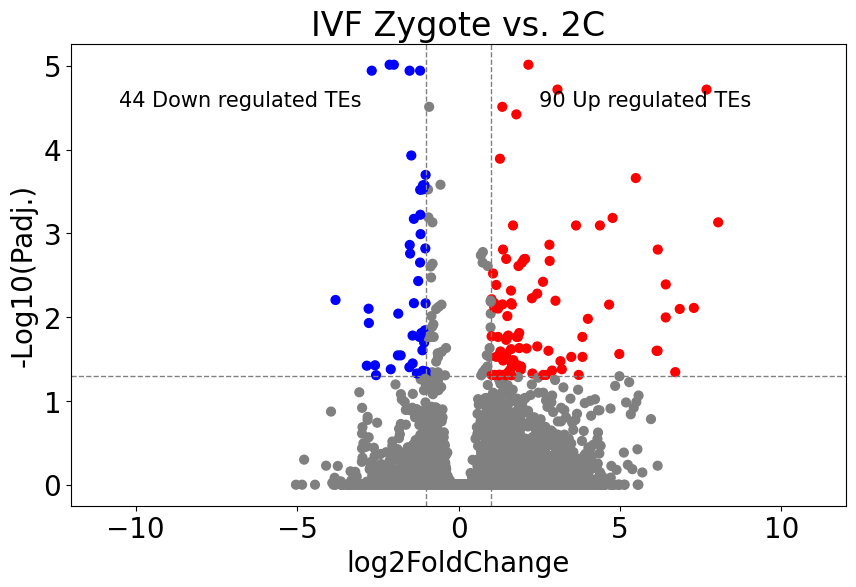

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'IVF_zygote_2c_TE_deseq2.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(padj)
data['-log10(pvalue)'] = -np.log10(data['padj'].replace(0, np.nan))

# 颜色分类
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理异常值
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(pvalue)'])

# 统计上下调
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated TEs: {up_count}")
print(f"Down-regulated TEs: {down_count}")

# 导出ID（假设第一列为ID）
id_col = data.columns[0]
up_genes[[id_col]].to_csv("IVF_Zygote_vs_2C_upregulated_TE.txt", sep="\t", index=False)
down_genes[[id_col]].to_csv("IVF_Zygote_vs_2C_downregulated_TE.txt", sep="\t", index=False)

# 绘图
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10,6))

# 散点图栅格化
plt.scatter(
    data['log2FoldChange'],
    data['-log10(pvalue)'],
    c=data['color'],
    s=40,
    rasterized=True
)

# 阈值线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

max_value = data['-log10(pvalue)'].max()

# 文字注释保持矢量
plt.text(-10.5, max_value * 0.9, f'{down_count} Down regulated TEs',
         horizontalalignment='left', color='black', fontsize=15)
plt.text(2.5, max_value * 0.9, f'{up_count} Up regulated TEs',
         horizontalalignment='left', color='black', fontsize=15)

plt.title('IVF Zygote vs. 2C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# 保存为 SVG，dpi 控制栅格部分清晰度
plt.savefig(
    'IVF_Zygote_2C_TE_volcano.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated TEs: 25629
Down-regulated TEs: 18871


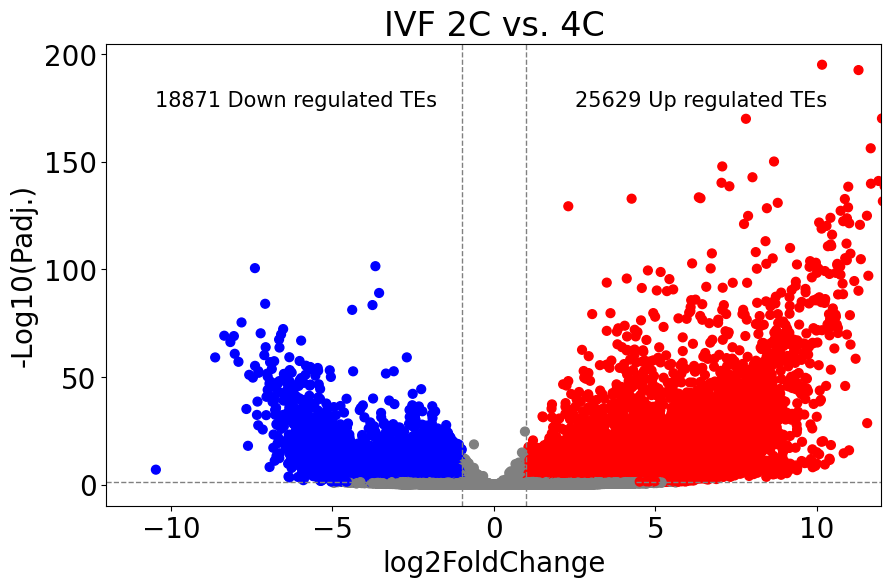

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'IVF_2c_4c_TE_deseq2.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(padj)
data['-log10(padj)'] = -np.log10(data['padj'].replace(0, np.nan))

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理无穷值及缺失值
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# 统计上下调基因
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated TEs: {up_count}")
print(f"Down-regulated TEs: {down_count}")

# 导出显著基因 ID（假设第一列为基因/特征名）
id_col = data.columns[0]
up_genes[[id_col]].to_csv("IVF_2C_vs_4C_upregulated_TE.txt", sep="\t", index=False)
down_genes[[id_col]].to_csv("IVF_2C_vs_4C_downregulated_TE.txt", sep="\t", index=False)

# 绘图设置
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

max_value = data['-log10(padj)'].max()

# 矢量文字注释（始终清晰）
plt.text(
    -10.5, max_value * 0.9,
    f'{down_count} Down regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)
plt.text(
    2.5, max_value * 0.9,
    f'{up_count} Up regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)

# 坐标轴与标题
plt.title('IVF 2C vs. 4C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'IVF_2C_4C_TE_volcano.svg',
    dpi=300,                  # 控制位图分辨率
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated TEs: 8388
Down-regulated TEs: 13500


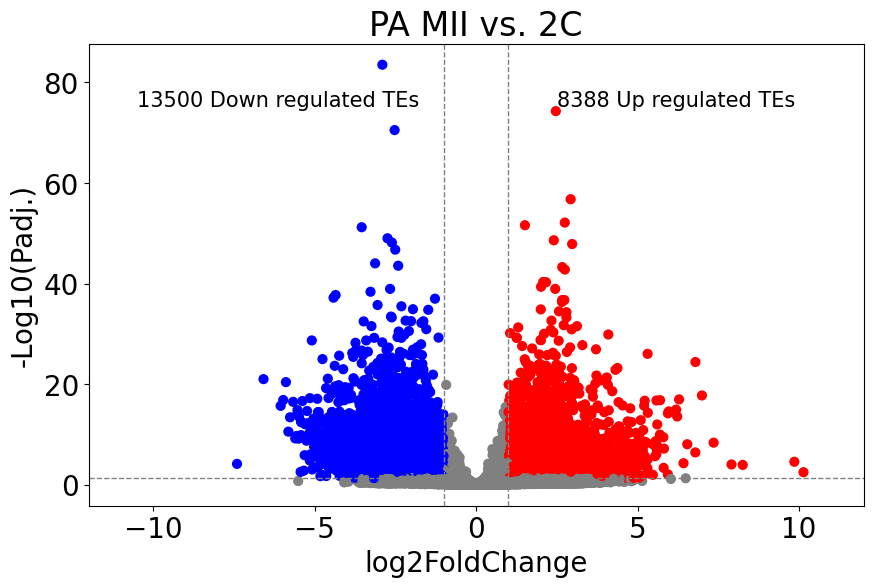

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'PA_MII_2c_TE_deseq2.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'].replace(0, np.nan))

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理异常值
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# 统计上下调
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated TEs: {up_count}")
print(f"Down-regulated TEs: {down_count}")

# 导出显著基因 ID（假设第一列为基因/特征名）
id_col = data.columns[0]
up_genes[[id_col]].to_csv("PA_MII_vs_2C_upregulated_TE.txt", sep="\t", index=False)
down_genes[[id_col]].to_csv("PA_MII_vs_2C_downregulated_TE.txt", sep="\t", index=False)

# 绘图设置
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

max_value = data['-log10(padj)'].max()

# 矢量文字注释（始终清晰）
plt.text(
    -10.5, max_value * 0.9,
    f'{down_count} Down regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)
plt.text(
    2.5, max_value * 0.9,
    f'{up_count} Up regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)

# 坐标轴与标题
plt.title('PA MII vs. 2C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'PA_MII_2C_TE_volcano.svg',
    dpi=300,                  # 控制位图分辨率
    bbox_inches='tight',
    transparent=True
)
plt.show()

Up-regulated TEs: 43682
Down-regulated TEs: 14148


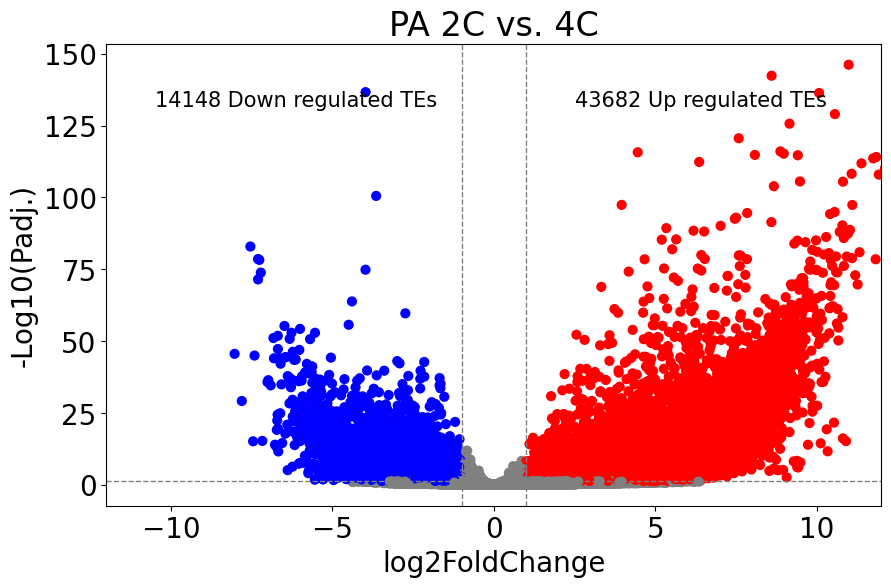

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# 读取数据
file_path = 'PA_2c_4c_TE_deseq2.txt'
data = pd.read_csv(file_path, sep='\t')

# 计算 -log10(padj)（规范列名）
data['-log10(padj)'] = -np.log10(data['padj'].replace(0, np.nan))

# 颜色分类（基于 padj 和 log2FoldChange）
def color_condition(row):
    if row['padj'] >= 0.05:
        return 'grey'
    elif row['padj'] < 0.05 and row['log2FoldChange'] > 1:
        return 'red'
    elif row['padj'] < 0.05 and row['log2FoldChange'] < -1:
        return 'blue'
    else:
        return 'grey'

data['color'] = data.apply(color_condition, axis=1)

# 清理异常值
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=['log2FoldChange', '-log10(padj)'])

# 统计上下调
up_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] > 1)]
down_genes = data[(data['padj'] < 0.05) & (data['log2FoldChange'] < -1)]
up_count = up_genes.shape[0]
down_count = down_genes.shape[0]

print(f"Up-regulated TEs: {up_count}")
print(f"Down-regulated TEs: {down_count}")

# 导出显著基因 ID（假设第一列为基因/特征名）
id_col = data.columns[0]
up_genes[[id_col]].to_csv("PA_2C_vs_4C_upregulated_TE.txt", sep="\t", index=False)
down_genes[[id_col]].to_csv("PA_2C_vs_4C_downregulated_TE.txt", sep="\t", index=False)

# 绘图设置
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(10, 6))

# 散点图 - 栅格化处理（关键优化）
plt.scatter(
    data['log2FoldChange'],
    data['-log10(padj)'],
    c=data['color'],
    s=40,
    rasterized=True          # 散点转为位图，文字保持矢量
)

# 阈值辅助线
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=1)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=1)

max_value = data['-log10(padj)'].max()

# 矢量文字注释（始终清晰）
plt.text(
    -10.5, max_value * 0.9,
    f'{down_count} Down regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)
plt.text(
    2.5, max_value * 0.9,
    f'{up_count} Up regulated TEs',
    horizontalalignment='left',
    color='black',
    fontsize=15
)

# 坐标轴与标题
plt.title('PA 2C vs. 4C')
plt.xlabel('log2FoldChange')
plt.ylabel('-Log10(Padj.)')
plt.xlim(-12, 12)

# 保存为 SVG（内部位图 + 矢量文字）
plt.savefig(
    'PA_2C_4C_TE_volcano.svg',
    dpi=300,                  # 控制位图分辨率
    bbox_inches='tight',
    transparent=True
)
plt.show()